# Multilayer Formalisms

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/05-xrays/07-multilayer_formalisms.ipynb)

In this example the multilayer formalisms of the {py:mod}`scattering <udkm1Dsim.simulations.scattering>` package are compared for the W/Fe/W trilayer of {cite:t}`elzo2012`.
All of them calculate the reflectivity and transmissivity of a stack of homogeneous layers from their dielectric tensor $\varepsilon_{ij}$, see the [example of the dielectric functions](#example_dielectric), from the X-ray to the optical range.
They differ only in the eigenmodes of the layers and in the assembly of the stack:

| formalism | eigenmodes | assembly | magnetization | anisotropic $\varepsilon^0$ | role |
|---|---|---|---|---|---|
| {py:class}`Parratt <udkm1Dsim.simulations.scattering.parratt.Parratt>` | scalar $\sigma$ and $\pi$ | recursion | neglected | no | fastest non-magnetic choice |
| {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` | analytical, first order in $\varepsilon^m$ | transfer matrices | arbitrary | no | fast magnetic formalism |
| {py:class}`Stepanov <udkm1Dsim.simulations.scattering.stepanov.Stepanov>` | analytical, first order in $\varepsilon^m$ | scattering matrices | arbitrary | no | thick, absorbing, or repeated stacks |
| {py:class}`BerremanElzo <udkm1Dsim.simulations.scattering.berreman.BerremanElzo>` | exact | transfer matrices | arbitrary | yes | comparison |
| {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>` | exact | scattering matrices | arbitrary | yes | reference calculation |

The formalism of {cite:t}`elzo2012` was formerly called `XrayDynMag`, which was removed in version 3.0.0.
All formalisms except `Parratt` were ported from [Dyna](https://gitlab.com/dynadevgroup/Dyna).

:::{admonition} References {cite}`elzo2012,stepanov2000,berreman1972,parratt1954`
:class: seealso
- M. Elzo, et al., *X-ray resonant magnetic reflectivity of stratified magnetic structures: Eigenwave formalism and application to a W/Fe/W trilayer*, [J. Magn. Magn. Mater. 324, 105 (2012)](http://www.doi.org/10.1016/j.jmmm.2011.07.019)
- S. A. Stepanov and S. K. Sinha, *X-ray resonant reflection from magnetic multilayers: Recursion matrix algorithm*, [Phys. Rev. B 61, 15302 (2000)](http://www.doi.org/10.1103/PhysRevB.61.15302)
- D. W. Berreman, *Optics in Stratified and Anisotropic Media: 4x4-Matrix Formulation*, [J. Opt. Soc. Am. 62, 502 (1972)](http://www.doi.org/10.1364/JOSA.62.000502)
:::

## Setup

Do all necessary imports and settings.

In [1]:
from time import time

import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The trilayer of W(3.13 nm)/Fe(9.15 nm)/W(13.41 nm) on a sapphire substrate is built with the thicknesses, roughnesses, and densities of Table 1 of {cite:t}`elzo2012`.
Here a local file of the measured atomic form factors is used for Fe, as in the [resonant magnetic X-ray example](#example_resonant_magnetic_xray).
The Fe layer is magnetized in the film plane along $y$, i.e. in the plane of incidence, which is the longitudinal geometry.

In [2]:
W = ud.Atom("W")
Fe = ud.Atom("Fe", magnetization=(0, 1, 0), atomic_form_factor_path="./Fe.cf")
Al2O3 = ud.AtomMixed("Al2O3", name="Al2O3")
Al2O3.add_atom(ud.Atom("Al"), 2 / 5)
Al2O3.add_atom(ud.Atom("O"), 3 / 5)

In [3]:
layer_W_top = ud.AmorphousLayer(
    "W_top",
    "W top",
    atom=W,
    structural=ud.StructuralParameters(
        thickness=3.13 * u.nm, density=19300 * u.kg / u.m**3, roughness=0.14 * u.nm
    ),
)
layer_Fe = ud.AmorphousLayer(
    "Fe",
    "Fe",
    atom=Fe,
    structural=ud.StructuralParameters(
        thickness=9.15 * u.nm, density=7874 * u.kg / u.m**3, roughness=0.51 * u.nm
    ),
)
layer_W_bottom = ud.AmorphousLayer(
    "W_bottom",
    "W bottom",
    atom=W,
    structural=ud.StructuralParameters(
        thickness=13.41 * u.nm, density=19300 * u.kg / u.m**3, roughness=1.16 * u.nm
    ),
)
layer_Al2O3 = ud.AmorphousLayer(
    "Al2O3",
    "sapphire",
    atom=Al2O3,
    structural=ud.StructuralParameters(
        thickness=0 * u.nm, density=3874 * u.kg / u.m**3, roughness=0.59 * u.nm
    ),
)

All formalisms take the dielectric tensor of the layers, which is set from their atoms in the X-ray range.

In [4]:
for layer in [layer_W_top, layer_Fe, layer_W_bottom, layer_Al2O3]:
    layer.set_dielectric_from_atoms()

S = ud.Structure("W/Fe/W")
S.add_sub_structure(layer_W_top, 1)
S.add_sub_structure(layer_Fe, 1)
S.add_sub_structure(layer_W_bottom, 1)
S.add_substrate(layer_Al2O3)
S

times,sub-structure,thickness
1,W top,3.13 nm
1,Fe,9.15 nm
1,W bottom,13.41 nm


## Reflectivity at 8051 eV

As in Fig. 6 of {cite:t}`elzo2012`, the reflectivity is calculated at the Cu $K_\alpha$ energy of 8051 eV far from any absorption edge of Fe for $\sigma$ polarization.
Here, all formalisms are initialized in the same way and their computation times are compared.

In [5]:
formalisms = [ud.Parratt, ud.Elzo, ud.Stepanov, ud.BerremanElzo, ud.BerremanStepanov]
theta = np.r_[0.2:2.6:0.002] * u.deg

R_8051 = {}
for formalism in formalisms:
    sim = formalism(S, True, save_data=False, disp_messages=False)
    sim.energy = np.r_[8051] * u.eV
    sim.theta = theta
    sim.set_polarization("sigma", "none")
    t0 = time()
    R_8051[formalism.__name__] = sim.homogeneous_reflectivity()[0][0, :]
    print(f"{formalism.__name__:17s} {(time() - t0) * 1e3:6.1f} ms")

Parratt              2.5 ms
Elzo                20.0 ms
Stepanov            18.9 ms
BerremanElzo        23.3 ms
BerremanStepanov    32.1 ms


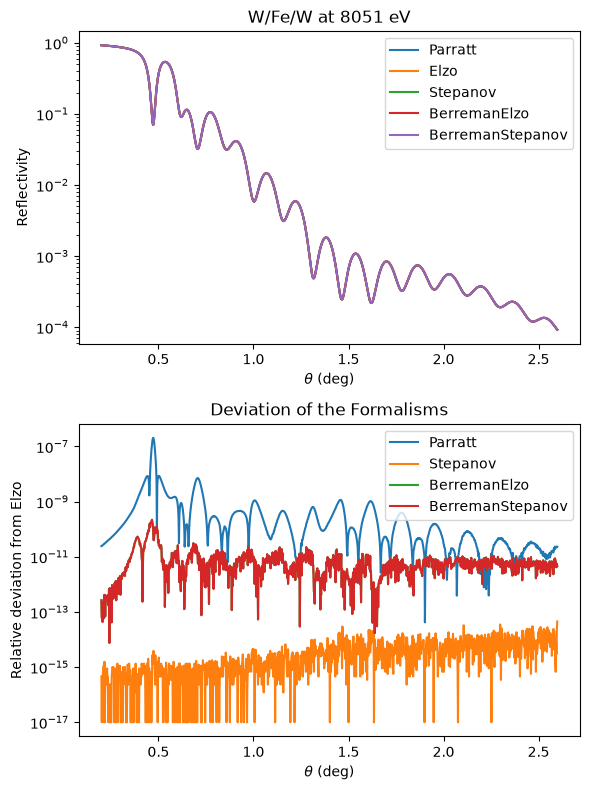

In [6]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for name, R in R_8051.items():
    plt.semilogy(theta, R, label=name)
plt.xlabel(r"$\theta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("W/Fe/W at 8051 eV")

plt.subplot(2, 1, 2)
for name, R in R_8051.items():
    if name != "Elzo":
        plt.semilogy(theta, np.abs(R / R_8051["Elzo"] - 1) + 1e-17, label=name)
plt.xlabel(r"$\theta$ (deg)")
plt.ylabel("Relative deviation from Elzo")
plt.legend()
plt.title("Deviation of the Formalisms")

plt.tight_layout()
plt.show()

Without magnetic contrast, all formalisms agree with each other within the numerical precision, while `Parratt` is by far the fastest one.
Only the small deviations of `Parratt` stem from its roughness factor of {cite:t}`nevot1980`, which differs slightly from the roughness matrices of the other formalisms.

## Magnetic Asymmetry at the Fe $L_{3,2}$ Edges

As in Fig. 8 of {cite:t}`elzo2012`, the magnetic asymmetry $(R^+ - R^-)/(R^+ + R^-)$ is calculated as function of the photon energy at a grazing angle of 10° for the longitudinal and transverse geometry.
The reflectivities $R^\pm$ for the opposite magnetizations are returned by all formalisms at once.
The longitudinal magnetization along $y$ is probed by circularly polarized light, while the transverse magnetization along $x$ is probed by $\pi$ polarization.
`Parratt` is not included, as it neglects the magnetization.

In [7]:
energy = np.r_[690:740:0.1] * u.eV
geometries = {
    "longitudinal": {"magnetization": (0, 1, 0), "polarization": "circ +"},
    "transverse": {"magnetization": (1, 0, 0), "polarization": "pi"},
}
asymmetry = {}
for geometry, settings in geometries.items():
    layer_Fe.magnetization = settings["magnetization"]
    for formalism in [ud.Elzo, ud.Stepanov, ud.BerremanStepanov]:
        sim = formalism(S, True, save_data=False, disp_messages=False)
        sim.energy = energy
        sim.theta = np.r_[10] * u.deg
        sim.set_polarization(settings["polarization"], 0)
        R, R_phi, _, _ = sim.homogeneous_reflectivity()
        asymmetry[geometry, formalism.__name__] = ((R - R_phi) / (R + R_phi))[:, 0]

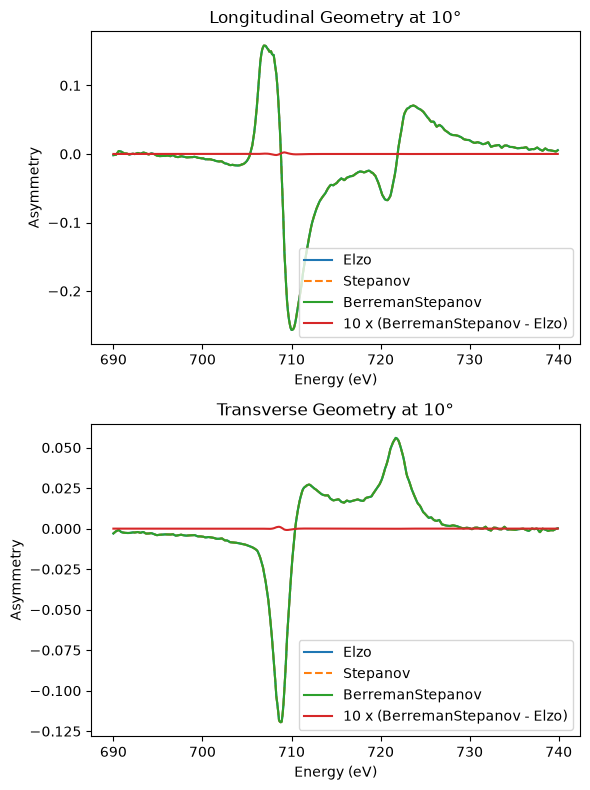

In [8]:
plt.figure(figsize=[6, 8])
for i, geometry in enumerate(geometries):
    plt.subplot(2, 1, i + 1)
    for name in ["Elzo", "Stepanov", "BerremanStepanov"]:
        style = "--" if name == "Stepanov" else "-"
        plt.plot(energy, asymmetry[geometry, name], style, label=name)
    plt.plot(
        energy,
        10 * (asymmetry[geometry, "BerremanStepanov"] - asymmetry[geometry, "Elzo"]),
        label="10 x (BerremanStepanov - Elzo)",
    )
    plt.xlabel("Energy (eV)")
    plt.ylabel("Asymmetry")
    plt.legend()
    plt.title(f"{geometry.capitalize()} Geometry at 10°")

plt.tight_layout()
plt.show()

`Elzo` and `Stepanov` share the analytical eigenmodes and give identical results.
The exact eigenmodes of `BerremanStepanov` deviate only to second order in the gyrotropic part $\varepsilon^m$ of the dielectric tensor, which is largest at the $L_3$ resonance.
Hence, a magnetic structure is typically fitted with the fast `Elzo` or `Stepanov` formalism and finally checked by `BerremanStepanov`.

The shape of the asymmetries follows Fig. 8 of {cite:t}`elzo2012`, while their magnitude depends on the tabulated magnetic form factors and the magnetic moment of the Fe layer, which were fitted in the paper.

## Numerical Stability

The transfer matrices of `Elzo` contain the exponentially growing terms of the modes propagating up through an absorbing layer.
Hence, they lose all numerical precision for thick, strongly absorbing, or highly repeated stacks, while the scattering-matrix recursion of {cite:t}`stepanov2000` stays stable.
This is demonstrated for a [Fe(3 nm)/W(2 nm)]$_N$ multilayer at the $L_3$ edge of Fe, which absorbs strongly.

In [9]:
layer_Fe.magnetization = (0, 1, 0)
period = ud.Structure("Fe/W")
period.add_sub_structure(layer_Fe, 1)
period.add_sub_structure(layer_W_bottom, 1)

repetitions = [10, 30, 100, 300, 1000]
theta = np.r_[5:60:0.5] * u.deg
R_rep = {}
for N in repetitions:
    S_ML = ud.Structure("multilayer")
    S_ML.add_sub_structure(period, N)
    S_ML.add_substrate(layer_Al2O3)
    for formalism in [ud.Elzo, ud.Stepanov]:
        sim = formalism(S_ML, True, save_data=False, disp_messages=False)
        sim.energy = np.r_[707] * u.eV
        sim.theta = theta
        sim.set_polarization("circ +", "none")
        with np.errstate(all="ignore"):
            R_rep[N, formalism.__name__] = sim.homogeneous_reflectivity()[0][0, :]

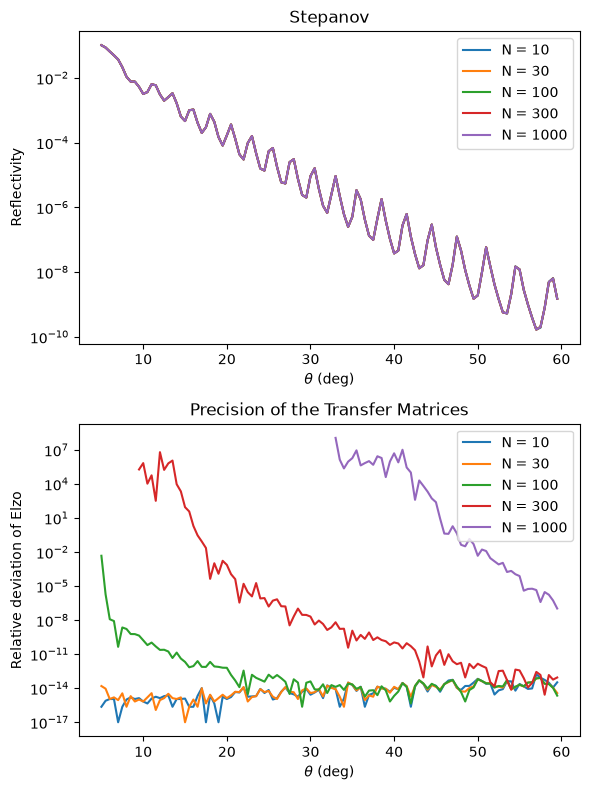

In [10]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for N in repetitions:
    plt.semilogy(theta, R_rep[N, "Stepanov"], label=f"N = {N:d}")
plt.xlabel(r"$\theta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Stepanov")

plt.subplot(2, 1, 2)
for N in repetitions:
    plt.semilogy(
        theta, np.abs(R_rep[N, "Elzo"] / R_rep[N, "Stepanov"] - 1) + 1e-17, label=f"N = {N:d}"
    )
plt.xlabel(r"$\theta$ (deg)")
plt.ylabel("Relative deviation of Elzo")
plt.legend()
plt.title("Precision of the Transfer Matrices")

plt.tight_layout()
plt.show()

For a few hundred periods, i.e. a total thickness of the order of a micrometer, the transfer matrices of `Elzo` become inaccurate and finally overflow, while the reflectivity of `Stepanov` converges to the one of the semi-infinite multilayer.